# Week 9 - Introduction to Neural Networks

**Thomas Sinclair**

### Aims

The main concepts covered in this notebook are: 

>* getting familiar with the basics of keras
>* input-output with keras
>* construction of neural network models with keras

This week, we will be exploring the basics of keras and building and fitting our first neural network with keras. For a quick introduction, please see https://keras.io/getting_started/intro_to_keras_for_engineers/

You may complete the worksheets together in teams of 2-3. When completing worksheets:

>- You will have tasks tagged by (CORE) and (EXTRA). 
>- Your primary aim is to complete the (CORE) components during the WS session, afterwards you can try to complete the (EXTRA) tasks for your self-learning process. 
>- In some Exercises, you will see some beneficial hints at the bottom of questions.

Instructions for submitting your workshops can be found at the end of worksheet. As a reminder, you must submit a pdf of your notebook on Learn by 16:00 PM on the first Monday after the day workshop was given.

# Setup <a id='setup'></a>

## Packages

Let's load the some of the packages needed for this workshop. **Note that, if using Noteable, you need to use a "Language and Machine Learning" kernel, not the "Standard Python 3" kernel we used for previous workshops.**

In [1]:
# Import necessary libraries
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Part 1: Simulated Data

In the first part of this workshop, we will work with a simple simulated example to gain some basic understanding of neural networks and keras. 

We generate $N=2500$ simulated data points. First we generate the labels assuming that:
$$  y_i \sim \text{Bern}(0.5).$$
Next, we generate the features of dimension $D=2$. The first feature is simulated uniformly in $[-\pi,\pi]$
$$x_{i,1} \sim \text{Uniform}(-\pi,\pi).$$
For the second feature, if $y=0$, then
$$x_{i,2} \sim \text{Norm}(\cos( x_{i,1}),\sigma^2).$$
Otherwise, if $y=1$, then
$$x_{i,2} \sim  \text{Norm}(1+ \cos( x_{i,1}),\sigma^2).$$

Once we created the data, we split it into 80% training data and 20% test data.

In [2]:
# Generate data
keras.utils.set_random_seed(11205)
N = 2500
D = 2
y = np.random.binomial(1, 0.5, N)
X = np.zeros((N, D))
X[:,0] = np.random.uniform(-np.pi, np.pi, N)
X[y == 0,1] = np.cos(X[y == 0,0]) + np.random.normal(0, 0.25, (y == 0).sum())
X[y == 1,1] = 1 + np.cos(X[y == 1,0]) + np.random.normal(0, 0.25, (y == 1).sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

### 🚩 Exercise 1 (CORE)

Plot the training data colored by the class labels. 

**EXTRA.** Derive the true decision boundary and add it to the plot. 

<Axes: >

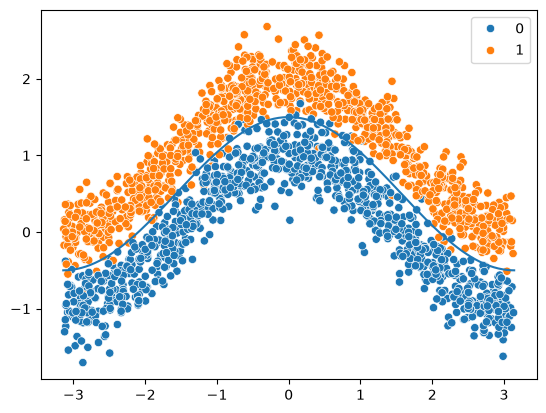

In [3]:
# Code for your answer here!
#X_train
x = np.linspace(-np.pi,np.pi,200)

sns.scatterplot(x = X_train[:,0], y = X_train[:,1], hue = y_train)
sns.lineplot(x = x, y = np.cos(x) +1/2)

**EXTRA.** Type your answer here

Decision boundary derived with, $\mathbb{P}(x_1 | y = 1, x_2) = \mathcal{N}(x_1 ; 1+ \cos( x_{1}),\sigma^2)$, and $\mathbb{P}(x_2 | y = 0, x_1) = \mathcal{N}(x_2 ; \cos(x_1), \sigma^2)$. y is  bernoulli rv, hence equal probabilities. Thus intersection of both occurs at:
$$
x_2 = \frac{cos(x_1) + 1 + cos(x_1)}{2} = cos(x_1) + \frac{1}{2}
$$

## Building a baseline logistic regression in keras

Let's start by building a logistic regression model in keras, using the `Functional` model: https://keras.io/guides/functional_api/ 

A `Functional` model provides a way to build a directed graph of `Layers` that connect to each other. `Layers` are the basic building blocks of neural networks in keras:  https://keras.io/api/layers/

To construct a logistic regression model, we only need two layers: 
- an input layer, which we construct using an `Input` layer: https://keras.io/api/layers/core_layers/input/ 
- an output layer, which we construct using a `Dense` layer: https://keras.io/api/layers/core_layers/dense/

In [4]:
# Defining the layers of the model
input_layer = keras.layers.Input(shape=(D,))
logit_layer = keras.layers.Dense(1, activation='sigmoid')

Then, we combine the layers and create our model which connects the input and output. 

In [5]:
output = logit_layer(input_layer)
model_lr = keras.models.Model(input_layer, output)
model_lr.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Print the number of layers in the model
print(len(model_lr.layers)) 

2


Alternatively, we can build the model using the `Sequential` model, see https://keras.io/api/models/sequential/ and https://keras.io/guides/sequential_model/. A `Sequential` model is esssentially a plain stack of `Layers` where each layer has exactly one input tensor and one output tensor, while a `Functional` model allows more general constructions (i.e. a graph of layers). 

In [7]:
model_lr2 = keras.Sequential(
    [
        keras.Input(shape=(D,)),
        keras.layers.Dense(1, activation='sigmoid'),
    ]
)
model_lr2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

Now, we are ready to compile the model: https://keras.io/api/models/model_training_apis/

When compiling, we need to specify:
- a loss function: https://keras.io/api/losses/
- an optimizer: https://keras.io/api/optimizers/
- (optionally) metrics: https://keras.io/api/metrics/

In [8]:
model_lr.compile(
    loss='binary_crossentropy', # or loss=keras.losses.BinaryCrossentropy(from_logits=False),
    optimizer='adam', # or  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=[
       keras.metrics.BinaryAccuracy(name='accuracy'),
       keras.metrics.AUC(name='auc')
    ],
)

### Training the model

Now, we are ready to to fit the model! We need to specifiy: 
- the number of `epochs` (which is the number of times that we cycle through the whole training data during gradient descent), 

and optionally various other parameters, such as 

- `shuffle` (e.g. `shuffle=True`), which specifies whether to shuffle the training data before each epoch.
- `validation_split` which is a float between 0 and 1, determining the fraction of the training data to be used as validation data. The model will set apart this fraction of the training data, will not train on it, and will evaluate the loss and any model metrics on this data at the end of each epoch. This is useful for **early stopping**, i.e. determining if training should be stopped early to prevent overfitting.
- `batch_size`: Integer or None. Number of samples per gradient update. If unspecified, batch_size will default to 32. 
For more details, see: https://keras.io/api/models/model_training_apis/

**Caution:** the data is not shuffled before splitting the data into a validation set. If the data are ordered in particular way when stored, then the training and validation sets can potentially characterize different populations. Thus, it is recommend to first shuffle the order of your data before fitting.  

In [9]:
# If you need to shuffle the training data before fitting uncomment the following lines
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, y_train, random_state=11205)

In [10]:
model_lr.fit(x=X_train, y=y_train, epochs=50, shuffle=True, validation_split=0.1)

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5289 - auc: 0.5647 - loss: 0.8410 - val_accuracy: 0.5700 - val_auc: 0.6141 - val_loss: 0.7911
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5306 - auc: 0.5826 - loss: 0.8058 - val_accuracy: 0.5600 - val_auc: 0.6349 - val_loss: 0.7605
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5344 - auc: 0.6055 - loss: 0.7730 - val_accuracy: 0.5600 - val_auc: 0.6621 - val_loss: 0.7323
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5394 - auc: 0.6331 - loss: 0.7428 - val_accuracy: 0.5650 - val_auc: 0.6865 - val_loss: 0.7066
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5411 - auc: 0.6648 - loss: 0.7153 - val_accuracy: 0.5750 - val_auc: 0.7070 - val_loss: 0.6835
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5472 - auc: 0.6942 - loss: 0.6903 - val_accuracy: 0.5850 - val_auc: 0.7266 - val_loss: 0.6630
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - 

Let's plot the metrics as a function of the number of epochs.

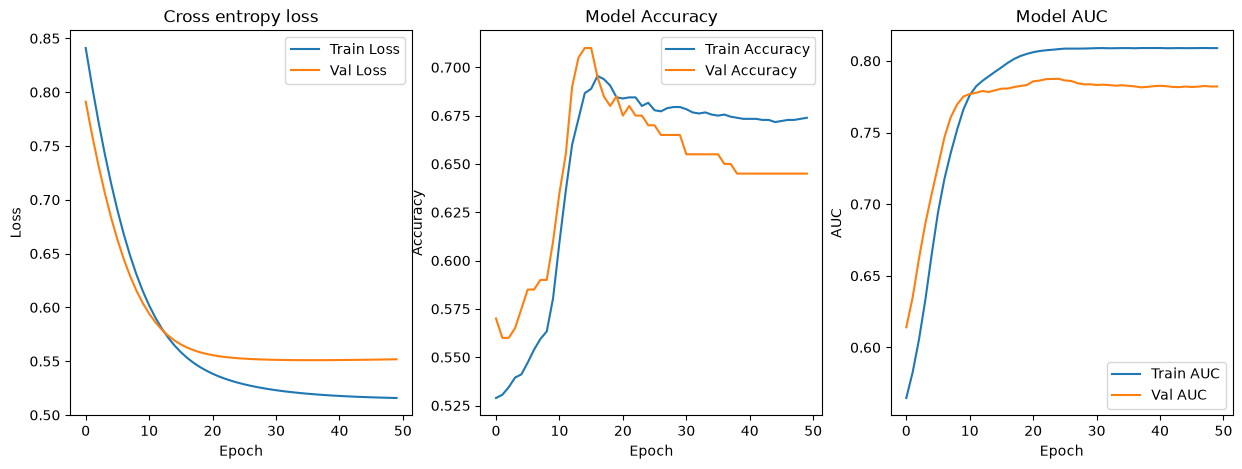

In [11]:
# Plot the training history
history = model_lr.history.history
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].plot(history['loss'], label='Train Loss')
ax[0].plot(history['val_loss'], label='Val Loss')
ax[0].set_title('Cross entropy loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[1].plot(history['accuracy'], label='Train Accuracy')
ax[1].plot(history['val_accuracy'], label='Val Accuracy')
ax[1].set_title('Model Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[2].plot(history['auc'], label='Train AUC')
ax[2].plot(history['val_auc'], label='Val AUC')
ax[2].set_title('Model AUC')
ax[2].set_xlabel('Epoch')
ax[2].set_ylabel('AUC')
ax[2].legend()
plt.show()

If you notice that the validation loss (and metrics) is still decreasing (increasing) as a function of epochs, this suggests that you may need to train the model longer.

If you notice that the validation loss (and metrics) starts to increase (decrease) as a function of epochs, this suggests that the model is starting to overfit. Based on this, we can determine the number of epochs to use based on the U-shape of the validation loss (this is known as early stopping, for more info see: https://keras.io/api/callbacks/early_stopping/). 

### Testing the model

Now, we can use `.predict()` to make predictions. Let's predict at the training points and draw a heatmap of the predicted probabilities.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 548us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step


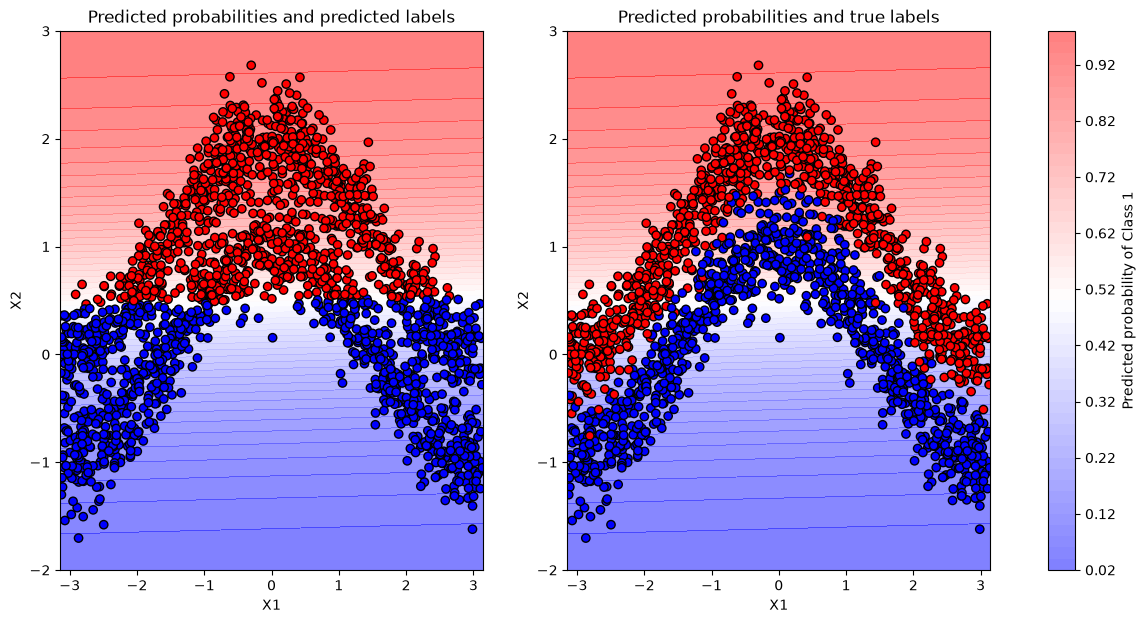

In [12]:
# Create a grid to plot probabilities
X_grid1, X_grid2 = np.meshgrid(np.linspace(-np.pi, np.pi, 100), np.linspace(-2, 3, 100))
X_grid = np.column_stack([X_grid1.ravel(), X_grid2.ravel()])

# Predict probabilities on grid
y_pred_prob_lr = model_lr.predict(X_grid)

# Predict probabilities for training points and predict a label
y_pred_prob_train = model_lr.predict(X_train)
y_train_pred_lr = (y_pred_prob_train >= 0.5).astype(int)

# # Draw a heatmap of the predicted probabilities
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

prob_plot = ax[0].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train_pred_lr, cmap="bwr", edgecolor="k")
ax[0].set_xlabel("X1")
ax[0].set_ylabel("X2")
ax[0].set_title("Predicted probabilities and predicted labels")

ax[1].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="bwr", edgecolor="k")
ax[1].set_xlabel("X1")
ax[1].set_ylabel("X2")
ax[1].set_title("Predicted probabilities and true labels")

fig.colorbar(prob_plot, ax=ax, label="Predicted probability of Class 1")
plt.show()


### 🚩 Exercise 2 (CORE)

- Compute the `classification_report` and `confusion_matrix` for the test data.
- Is the result what you expect, and why?

In [13]:
# Code for your answer here!
from sklearn.metrics import classification_report, confusion_matrix

y_pred_lr = model_lr.predict(X_test)
y_pred_lr_bi = (y_pred_lr >= 0.5).astype(int)

print(classification_report(y_true=y_test, y_pred=y_pred_lr_bi))

print(confusion_matrix(y_true=y_test,y_pred=y_pred_lr_bi))



16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
              precision    recall  f1-score   support

           0       0.67      0.66      0.67       246
           1       0.68      0.68      0.68       254

    accuracy                           0.67       500
   macro avg       0.67      0.67      0.67       500
weighted avg       0.67      0.67      0.67       500

[[163  83]
 [ 81 173]]


_Type your answer here_

This is pretty much the results we expect, as from the graph from core ex1, we see there are some points lying on the wrong sides of the decision boundary on both sides. Thus we expect Lower scores that occur due to more False positives and false negatives. This Increase number in FP and FN is seen from the confusion matrix.

### Adding a hidden layer

Now, let's add a hidden layer, with 2 neurons.

In [14]:
input_layer = keras.Input(shape=(D,))
hidden_layer = keras.layers.Dense(2, activation='relu')(input_layer)
output_layer = keras.layers.Dense(1, activation='sigmoid')(hidden_layer)
model_hidden2 = keras.Model(inputs=input_layer, outputs=output_layer)
model_hidden2.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

### 🚩 Exercise 3 (CORE)

Compile the model, train and plot the metrics as a function of epochs. 

Continue to train the model for more epochs as needed. Note: rerun the fit line will continue to train the model from where it left off.

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6739 - auc: 0.8090 - loss: 0.5157 - val_accuracy: 0.6450 - val_auc: 0.7820 - val_loss: 0.5519
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6733 - auc: 0.8090 - loss: 0.5156 - val_accuracy: 0.6450 - val_auc: 0.7818 - val_loss: 0.5520
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6728 - auc: 0.8089 - loss: 0.5155 - val_accuracy: 0.6450 - val_auc: 0.7814 - val_loss: 0.5521
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6722 - auc: 0.8089 - loss: 0.5154 - val_accuracy: 0.6450 - val_auc: 0.7817 - val_loss: 0.5522
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6722 - auc: 0.8090 - loss: 0.5153 - val_accuracy: 0.6450 - val_auc: 0.7818 - val_loss: 0.5523
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6722 - auc: 0.8090 - loss: 0.5152 - val_accuracy: 0.6450 - val_auc: 0.7816 - val_loss: 0.5524
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - 

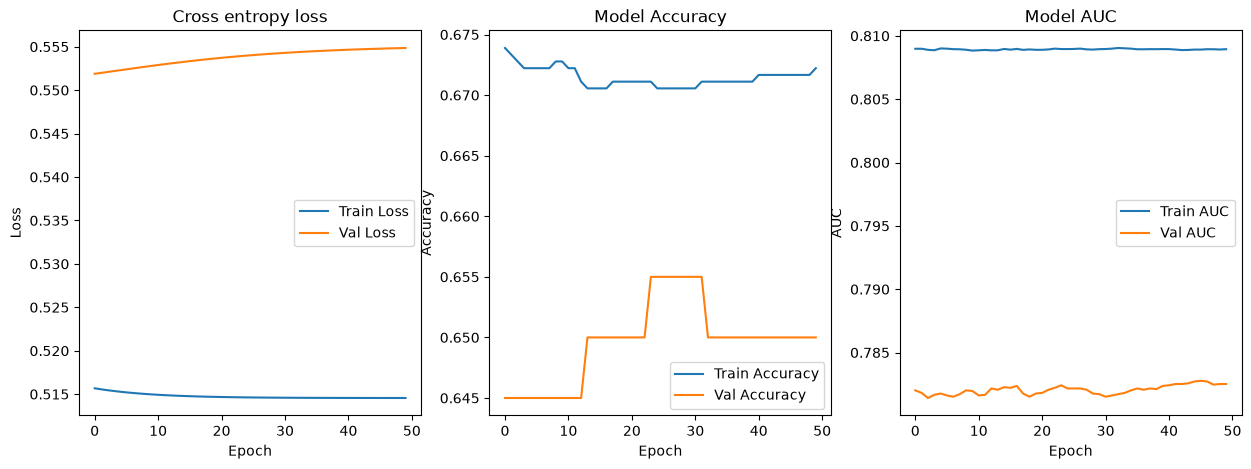

In [15]:
# Code for your answer here!

model_lr.fit(x=X_train, y=y_train, epochs=50, shuffle=True, validation_split=0.1)

# Plot the training history
history = model_lr.history.history
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].plot(history['loss'], label='Train Loss')
ax[0].plot(history['val_loss'], label='Val Loss')
ax[0].set_title('Cross entropy loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[1].plot(history['accuracy'], label='Train Accuracy')
ax[1].plot(history['val_accuracy'], label='Val Accuracy')
ax[1].set_title('Model Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[2].plot(history['auc'], label='Train AUC')
ax[2].plot(history['val_auc'], label='Val AUC')
ax[2].set_title('Model AUC')
ax[2].set_xlabel('Epoch')
ax[2].set_ylabel('AUC')
ax[2].legend()
plt.show()

### 🚩 Exercise 4 (CORE)

Draw a heatmap of the predicted probabilities. How does the model perform now?

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 457us/step


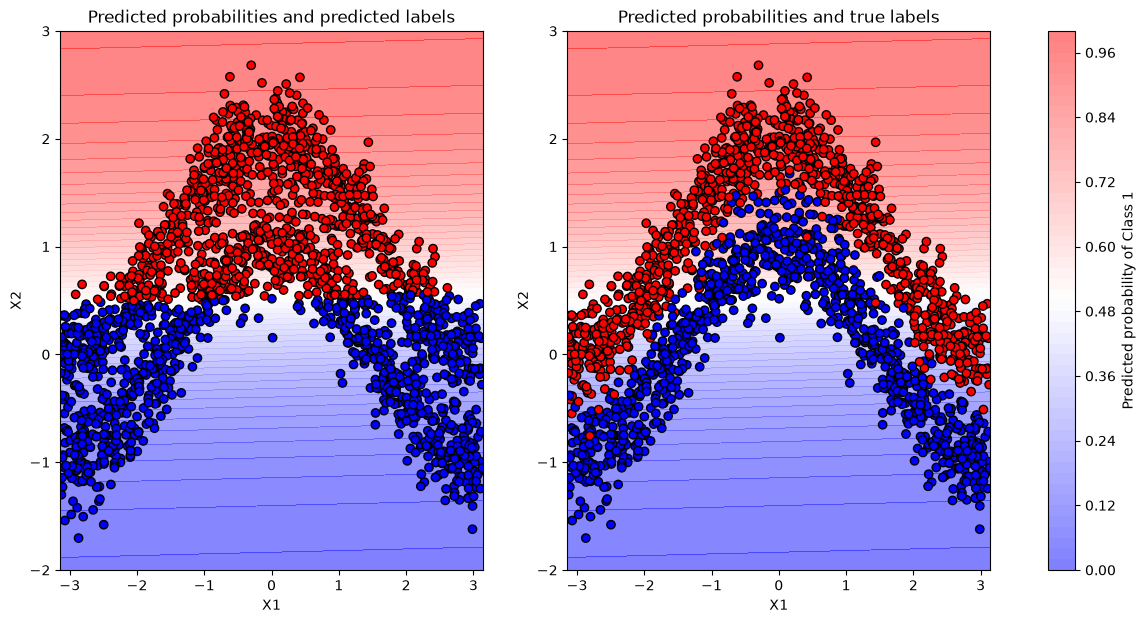

In [16]:
# Code for your answer here!

# Create a grid to plot probabilities
X_grid1, X_grid2 = np.meshgrid(np.linspace(-np.pi, np.pi, 100), np.linspace(-2, 3, 100))
X_grid = np.column_stack([X_grid1.ravel(), X_grid2.ravel()])

# Predict probabilities on grid
y_pred_prob_lr = model_lr.predict(X_grid)

# Predict probabilities for training points and predict a label
y_pred_prob_train = model_lr.predict(X_train)
y_train_pred_lr = (y_pred_prob_train >= 0.5).astype(int)

# # Draw a heatmap of the predicted probabilities
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

prob_plot = ax[0].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train_pred_lr, cmap="bwr", edgecolor="k")
ax[0].set_xlabel("X1")
ax[0].set_ylabel("X2")
ax[0].set_title("Predicted probabilities and predicted labels")

ax[1].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="bwr", edgecolor="k")
ax[1].set_xlabel("X1")
ax[1].set_ylabel("X2")
ax[1].set_title("Predicted probabilities and true labels")

fig.colorbar(prob_plot, ax=ax, label="Predicted probability of Class 1")
plt.show()


_Type your answer here_

The heatmap hasn't visually changed much from our last plot of the heatmap. This could be because the decision boundary hasn't changed significantly to where we can see the difference. 

### Visualising the output of each neuron

By visualising the output of each neuron, we can gain an understanding of the features extracted. 

In the code below, we create a keras model for the mapping of the inputs to the hidden layer and pass through the data. By plotting the output of the hidden layer, we observe that:
- the first hidden feature captures the separation of the two classes when $x_1<0$ and 
- the second hidden feature captures the separation of the two classes when $x_1>0$.

(This requires us to have fit the model well enough, you may have to train the model for more epochs!)

In [17]:
model_hidden2.compile( # NEEDED TO BE ADDED TO TRAIN FOR MORE EPOCHS
    loss='binary_crossentropy', # or loss=keras.losses.BinaryCrossentropy(from_logits=False),
    optimizer='adam', # or  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=[
       keras.metrics.BinaryAccuracy(name='accuracy'),
    ],
)

model_hidden2.fit(X_train, y_train,epochs=200)

# Extract the output of the hidden layer
hidden_layer_model = keras.Model(inputs=model_hidden2.input, outputs=model_hidden2.layers[1].output)

# Hidden output for the observed training data
z =hidden_layer_model(X_train)
# Convert to numpy array
z = z.numpy()

# Hidden output for the grid 
z_grid =hidden_layer_model(X_grid)
# Convert to numpy array
z_grid = z_grid.numpy()

Epoch 1/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5490 - loss: 0.7335 
Epoch 2/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step - accuracy: 0.5480 - loss: 0.7129
Epoch 3/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5540 - loss: 0.6982
Epoch 4/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 977us/step - accuracy: 0.5520 - loss: 0.6866
Epoch 5/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step - accuracy: 0.5475 - loss: 0.6759
Epoch 6/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5510 - loss: 0.6654  
Epoch 7/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5655 - loss: 0.6557
Epoch 8/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5685 - loss: 0.6472  
Epoch 9/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5770 - loss: 0.6395 
Epoch 10/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5805 - loss: 0.6322  
Epoch 11/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5845 - loss: 0.6251
Epoch 12/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/st

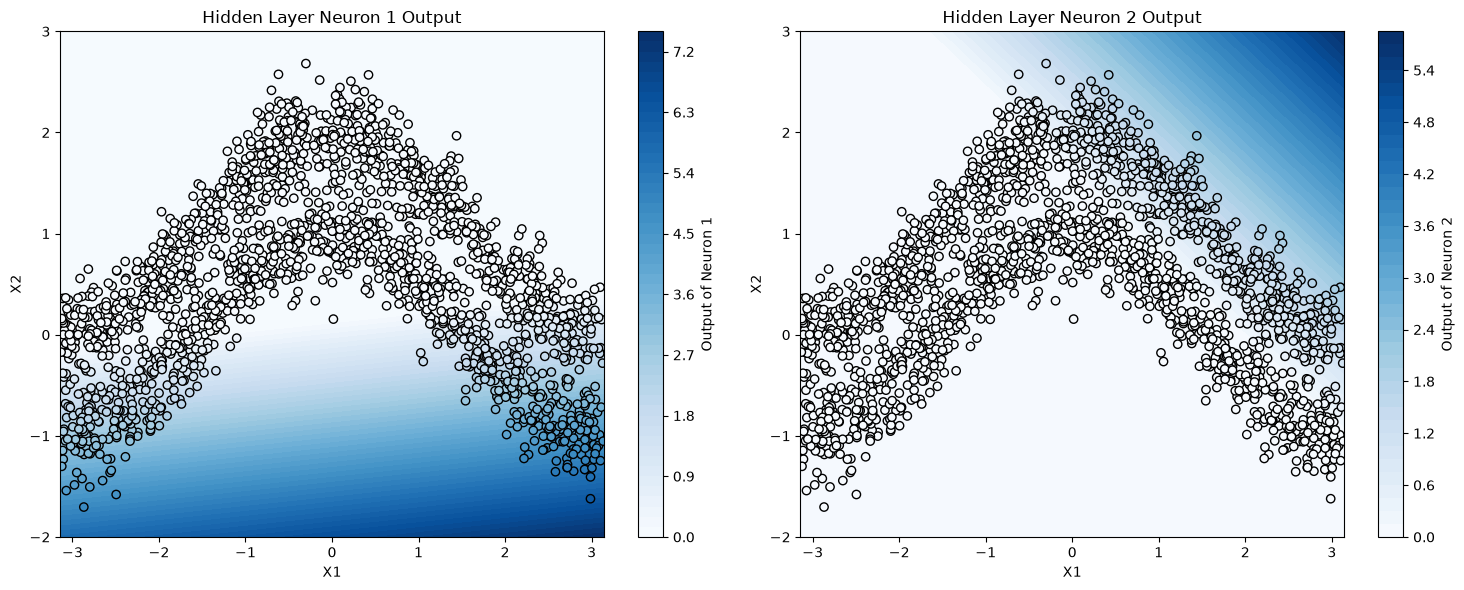

In [18]:
# Draw a heatmap of the output of the hidden layer neurons
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for i in range(2):
    vmin= min(z[:,i].min(), z_grid[:,i].min())   
    vmax= max(z[:,i].max(), z_grid[:,i].max())
    ax[i].contourf(X_grid1, X_grid2, z_grid[:,i].reshape(X_grid1.shape), levels=50, cmap='Blues', vmin=vmin, vmax=vmax)
    ax[i].scatter(X_train[:,0], X_train[:,1], c=z[:,i], cmap='Blues', edgecolor='k',vmin=vmin, vmax=vmax)
    ax[i].set_xlabel('X1')
    ax[i].set_ylabel('X2')
    ax[i].set_title(f'Hidden Layer Neuron {i+1} Output')
    cbar = plt.colorbar(ax[i].collections[0], ax=ax[i])
    cbar.set_label(f'Output of Neuron {i+1}')
fig.tight_layout() 
plt.show()

We can also print out the values of the weights and bias for each layer:

In [19]:
print('Hidden layer bias:', model_hidden2.layers[1].bias.numpy())
print('Hidden layer weights:', model_hidden2.layers[1].kernel.numpy())
print('Output layer bias:', model_hidden2.layers[2].bias.numpy())
print('Output layer weights:', model_hidden2.layers[2].kernel.numpy())

Hidden layer bias: [ 0.47791937 -2.2285783 ]
Hidden layer weights: [[ 0.2784498  1.1726487]
 [-3.0619473  1.4319577]]
Output layer bias: [-0.1197985]
Output layer weights: [[-1.5606502]
 [ 4.994097 ]]


### Increasing the width of the network

### 🚩 Exercise 5 (CORE)

Now, try increasing the number of hidden units to 5.
- Define and compile the model.
- Fit the model and train for as many epochs find are needed.
- Draw a heatmap of the predicted probabilities over the grid of input values.
- Draw heatmaps of the output for each hidden unit over the grid of input values.

Comment on how the predictions have changed and what features appear to be extracted by each hidden unit. Which model would you choose and why?

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5100 - loss: 0.7274 
Epoch 2/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5210 - loss: 0.6841
Epoch 3/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5535 - loss: 0.6542
Epoch 4/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6500 - loss: 0.6312  
Epoch 5/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7090 - loss: 0.6127  
Epoch 6/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7030 - loss: 0.5965 
Epoch 7/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7070 - loss: 0.5813  
Epoch 8/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7255 - loss: 0.5645 
Epoch 9/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7425 - loss: 0.5414  
Epoch 10/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7575 - loss: 0.5225  
Epoch 11/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7715 - loss: 0.5049 
Epoch 12/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/st

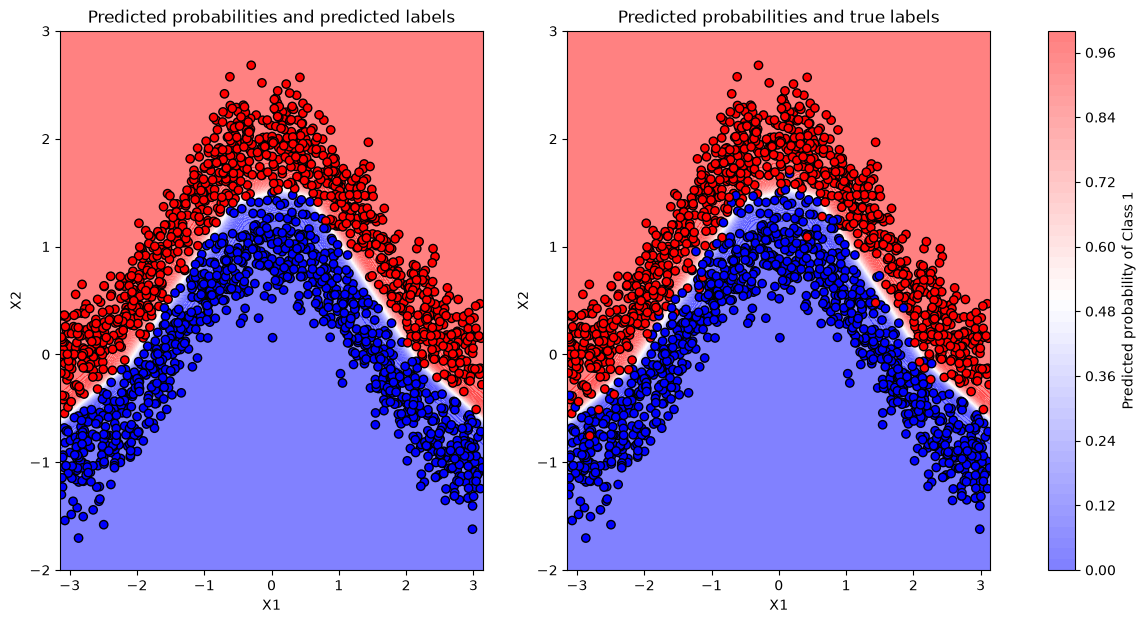

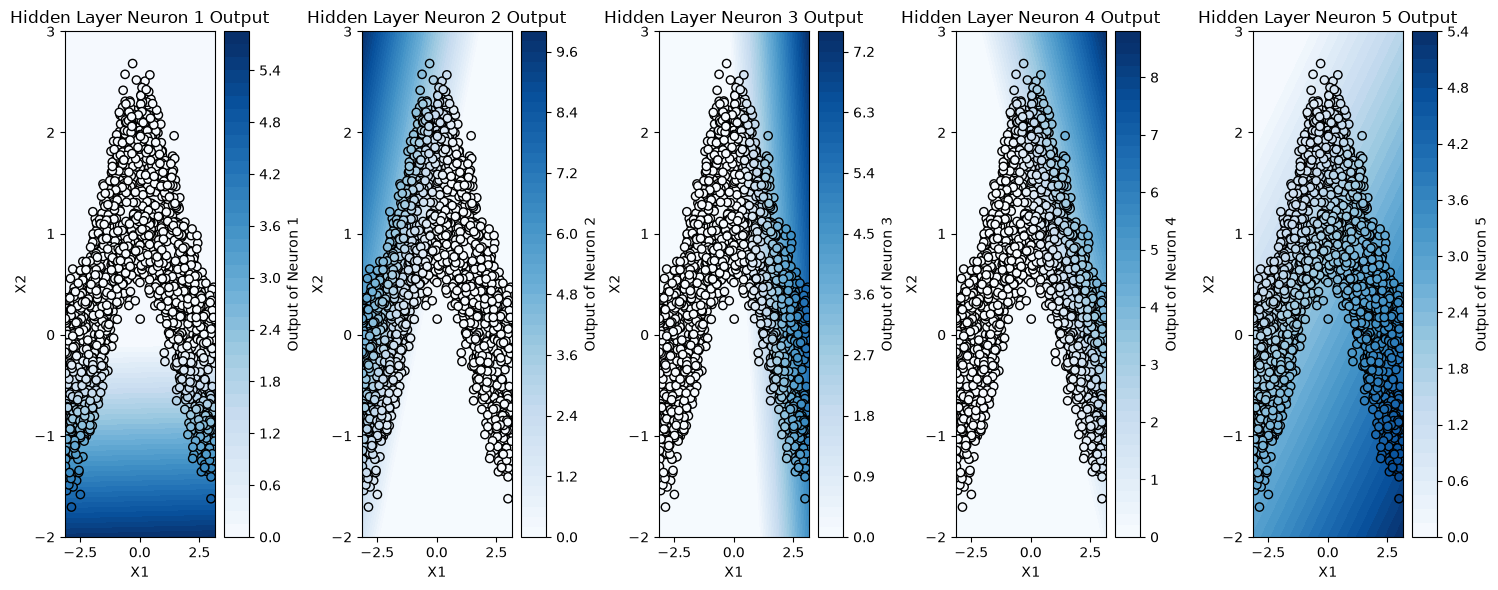

In [20]:
# Code for your answer here!

input_layer = keras.Input(shape=(D,))
hidden_layer = keras.layers.Dense(5, activation='relu')(input_layer)
output_layer = keras.layers.Dense(1, activation='sigmoid')(hidden_layer)
model_hidden3 = keras.Model(inputs=input_layer, outputs=output_layer)
model_hidden3.summary()

model_hidden3.compile( # NEEDED TO BE ADDED TO TRAIN FOR MORE EPOCHS
    loss='binary_crossentropy', # or loss=keras.losses.BinaryCrossentropy(from_logits=False),
    optimizer='adam', # or  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=[
       keras.metrics.BinaryAccuracy(name='accuracy'),
    ],
)

model_hidden3.fit(X_train, y_train,epochs=200)



# Create a grid to plot probabilities
X_grid1, X_grid2 = np.meshgrid(np.linspace(-np.pi, np.pi, 100), np.linspace(-2, 3, 100))
X_grid = np.column_stack([X_grid1.ravel(), X_grid2.ravel()])

# Predict probabilities on grid
y_pred_prob_lr = model_hidden3.predict(X_grid)

# Predict probabilities for training points and predict a label
y_pred_prob_train = model_hidden3.predict(X_train)
y_train_pred_lr = (y_pred_prob_train >= 0.5).astype(int)

# # Draw a heatmap of the predicted probabilities
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

prob_plot = ax[0].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train_pred_lr, cmap="bwr", edgecolor="k")
ax[0].set_xlabel("X1")
ax[0].set_ylabel("X2")
ax[0].set_title("Predicted probabilities and predicted labels")

ax[1].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="bwr", edgecolor="k")
ax[1].set_xlabel("X1")
ax[1].set_ylabel("X2")
ax[1].set_title("Predicted probabilities and true labels")

fig.colorbar(prob_plot, ax=ax, label="Predicted probability of Class 1")
plt.show()



# Extract the output of the hidden layer
hidden_layer_model = keras.Model(inputs=model_hidden3.input, outputs=model_hidden3.layers[1].output)

# Hidden output for the observed training data
z =hidden_layer_model(X_train)
# Convert to numpy array
z = z.numpy()

# Hidden output for the grid 
z_grid =hidden_layer_model(X_grid)
# Convert to numpy array
z_grid = z_grid.numpy()

# Draw a heatmap of the output of the hidden layer neurons
fig, ax = plt.subplots(1, 5, figsize=(15, 6))
for i in range(5):
    vmin= min(z[:,i].min(), z_grid[:,i].min())   
    vmax= max(z[:,i].max(), z_grid[:,i].max())
    ax[i].contourf(X_grid1, X_grid2, z_grid[:,i].reshape(X_grid1.shape), levels=50, cmap='Blues', vmin=vmin, vmax=vmax)
    ax[i].scatter(X_train[:,0], X_train[:,1], c=z[:,i], cmap='Blues', edgecolor='k',vmin=vmin, vmax=vmax)
    ax[i].set_xlabel('X1')
    ax[i].set_ylabel('X2')
    ax[i].set_title(f'Hidden Layer Neuron {i+1} Output')
    cbar = plt.colorbar(ax[i].collections[0], ax=ax[i])
    cbar.set_label(f'Output of Neuron {i+1}')
fig.tight_layout() 
plt.show()

_Type your answer here_

The precdictions have changed drastically. The model now predicts the non-linearity of the data, the U-shape of the data points. Eaxh hidden feature specialises in one deature so. If x2<0 hidden neuron 1 is extracted, as well as hidden neuron 2. If x1>0 and x2>0 we have hidden neuron 3, and 4 are extracted. And finallt if x1<0 and x2>0 then neuron 5 is extracted. I would choose this model, as it predicts the true data the best.

### Increasing the depth of the network

### 🚩 Exercise 6 (CORE)

Now, consider a model with two layers: 5 hidden units in the first layer and 2 hidden units in the second layer.
- Define and compile the model.
- Fit the model and train for as many epochs find are needed.
- Draw a heatmap of the predicted probabilities over the grid of input values.
- Draw heatmaps of the output for each hidden unit (in both layers) over the grid of input values.

Comment on how the predictions have changed and differences in the features extracted by the second layer compared to the first. Which model would you choose and why?

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30 (120.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5735 - loss: 0.7680 
Epoch 2/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5990 - loss: 0.6844
Epoch 3/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5915 - loss: 0.6395  
Epoch 4/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6450 - loss: 0.6106  
Epoch 5/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6720 - loss: 0.5897
Epoch 6/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6940 - loss: 0.5729
Epoch 7/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7095 - loss: 0.5601
Epoch 8/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7170 - loss: 0.5488  
Epoch 9/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 964us/step - accuracy: 0.7260 - loss: 0.5382
Epoch 10/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7365 - loss: 0.5274  
Epoch 11/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7505 - loss: 0.5160
Epoch 12/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

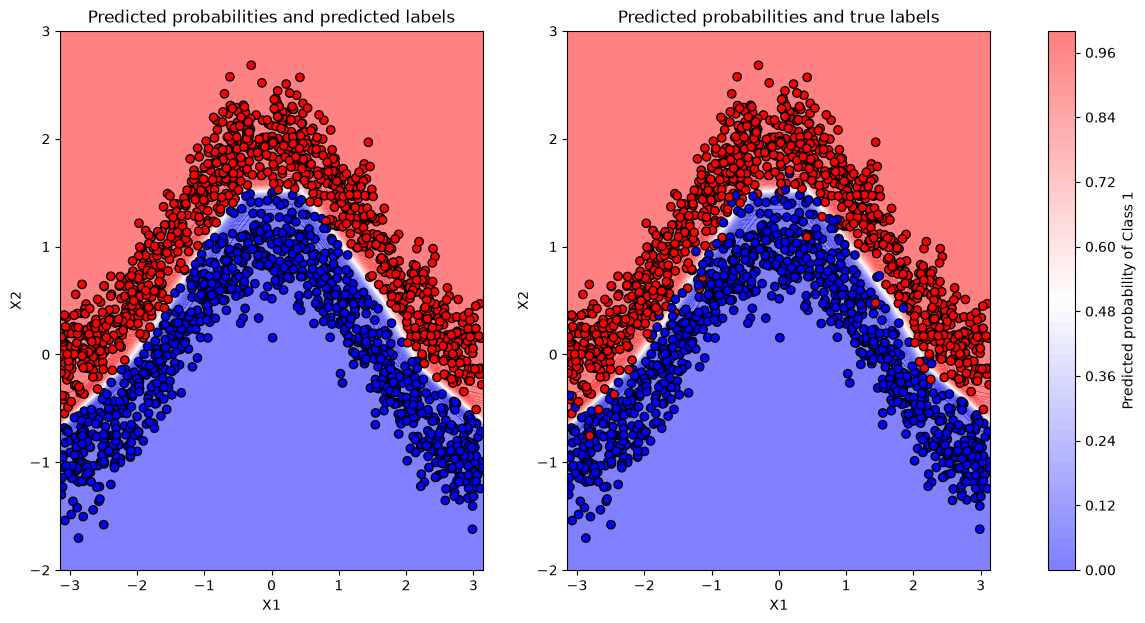

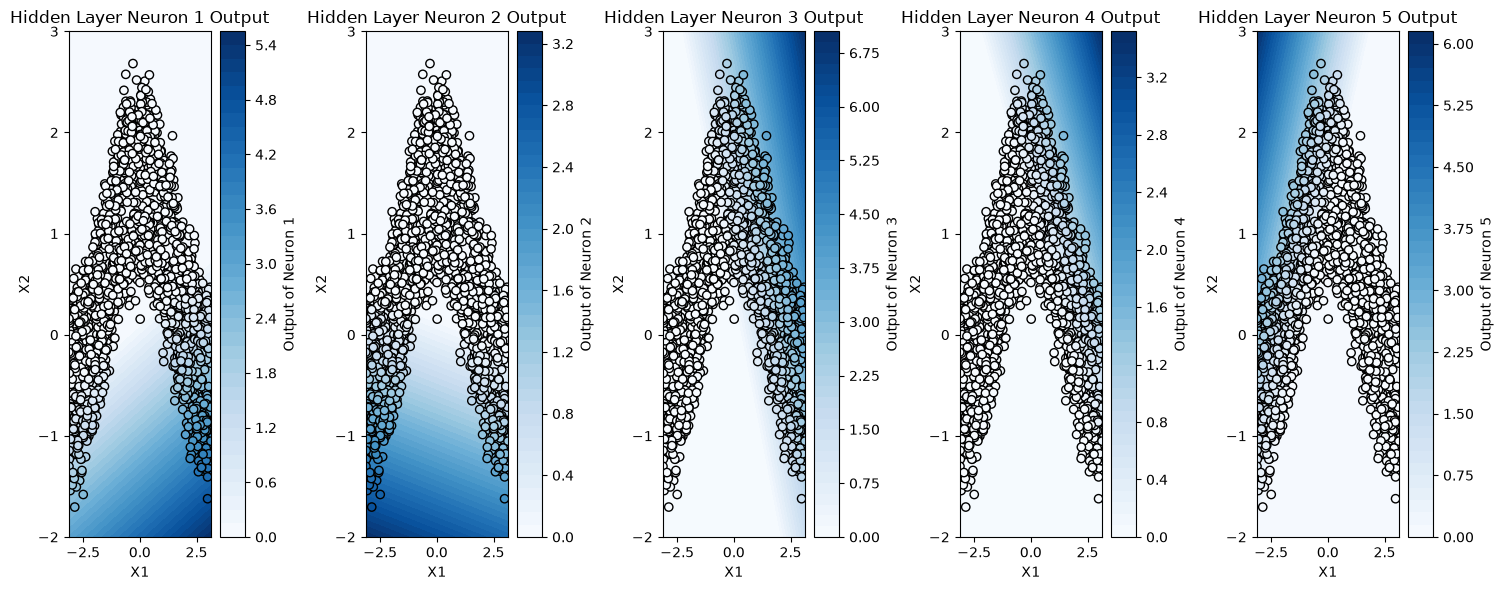

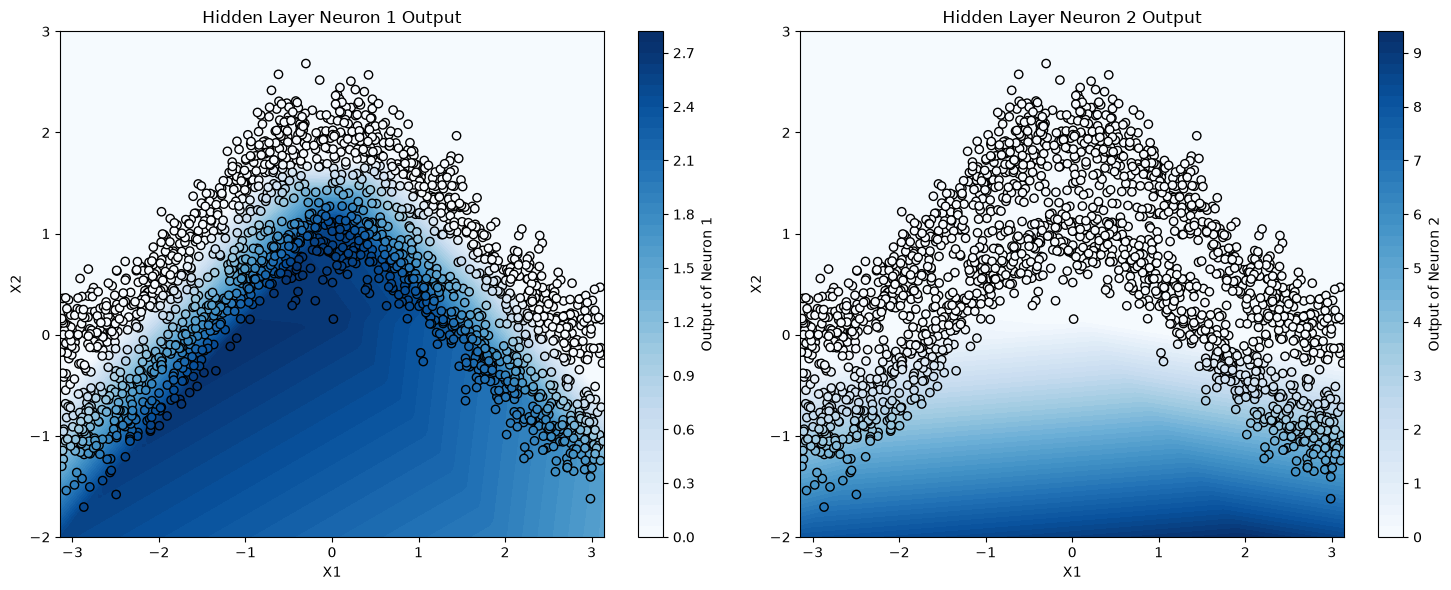

In [21]:
# Code for your answer here!

input_layer = keras.Input(shape=(D,))
hidden_layer = keras.layers.Dense(5, activation='relu')(input_layer)
hidden_layer1 = keras.layers.Dense(2, activation='relu')(hidden_layer)
output_layer = keras.layers.Dense(1, activation='sigmoid')(hidden_layer1)
model_hidden3 = keras.Model(inputs=input_layer, outputs=output_layer)
model_hidden3.summary()

model_hidden3.compile( # NEEDED TO BE ADDED TO TRAIN FOR MORE EPOCHS
    loss='binary_crossentropy', # or loss=keras.losses.BinaryCrossentropy(from_logits=False),
    optimizer='adam', # or  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=[
       keras.metrics.BinaryAccuracy(name='accuracy'),
    ],
)

model_hidden3.fit(X_train, y_train,epochs=200)



# Create a grid to plot probabilities
X_grid1, X_grid2 = np.meshgrid(np.linspace(-np.pi, np.pi, 100), np.linspace(-2, 3, 100))
X_grid = np.column_stack([X_grid1.ravel(), X_grid2.ravel()])

# Predict probabilities on grid
y_pred_prob_lr = model_hidden3.predict(X_grid)

# Predict probabilities for training points and predict a label
y_pred_prob_train = model_hidden3.predict(X_train)
y_train_pred_lr = (y_pred_prob_train >= 0.5).astype(int)

# # Draw a heatmap of the predicted probabilities
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

prob_plot = ax[0].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train_pred_lr, cmap="bwr", edgecolor="k")
ax[0].set_xlabel("X1")
ax[0].set_ylabel("X2")
ax[0].set_title("Predicted probabilities and predicted labels")

ax[1].contourf(
    X_grid1, X_grid2,
    y_pred_prob_lr.reshape(X_grid1.shape),
    levels=50, cmap="bwr", alpha=0.5
)
ax[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="bwr", edgecolor="k")
ax[1].set_xlabel("X1")
ax[1].set_ylabel("X2")
ax[1].set_title("Predicted probabilities and true labels")

fig.colorbar(prob_plot, ax=ax, label="Predicted probability of Class 1")
plt.show()



# Extract the output of the hidden layer
hidden_layer_model_l1 = keras.Model(inputs=model_hidden3.input, outputs=model_hidden3.layers[1].output)
hidden_layer_model_l2 = keras.Model(inputs=model_hidden3.input, outputs=model_hidden3.layers[2].output)

# Hidden output for the observed training data
z_l1 =hidden_layer_model_l1(X_train)
z_l2 =hidden_layer_model_l2(X_train)
# Convert to numpy array
z_l1 = z_l1.numpy()
z_l2 = z_l2.numpy()

# Hidden output for the grid 
z_grid_l1 =hidden_layer_model_l1(X_grid)
# Convert to numpy array
z_grid_l1 = z_grid_l1.numpy()

# Hidden output for the grid 
z_grid_l2 =hidden_layer_model_l2(X_grid)
# Convert to numpy array
z_grid_l2 = z_grid_l2.numpy()

# Draw a heatmap of the output of the hidden layer neurons
fig, ax = plt.subplots(1, 5, figsize=(15, 6))
for i in range(5):
    vmin= min(z_l1[:,i].min(), z_grid_l1[:,i].min())   
    vmax= max(z_l1[:,i].max(), z_grid_l1[:,i].max())
    ax[i].contourf(X_grid1, X_grid2, z_grid_l1[:,i].reshape(X_grid1.shape), levels=50, cmap='Blues', vmin=vmin, vmax=vmax)
    ax[i].scatter(X_train[:,0], X_train[:,1], c=z_l1[:,i], cmap='Blues', edgecolor='k',vmin=vmin, vmax=vmax)
    ax[i].set_xlabel('X1')
    ax[i].set_ylabel('X2')
    ax[i].set_title(f'Hidden Layer Neuron {i+1} Output')
    cbar = plt.colorbar(ax[i].collections[0], ax=ax[i])
    cbar.set_label(f'Output of Neuron {i+1}')
fig.tight_layout() 
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for i in range(2):
    vmin= min(z_l2[:,i].min(), z_grid_l2[:,i].min())   
    vmax= max(z_l2[:,i].max(), z_grid_l2[:,i].max())
    ax[i].contourf(X_grid1, X_grid2, z_grid_l2[:,i].reshape(X_grid1.shape), levels=50, cmap='Blues', vmin=vmin, vmax=vmax)
    ax[i].scatter(X_train[:,0], X_train[:,1], c=z_l2[:,i], cmap='Blues', edgecolor='k',vmin=vmin, vmax=vmax)
    ax[i].set_xlabel('X1')
    ax[i].set_ylabel('X2')
    ax[i].set_title(f'Hidden Layer Neuron {i+1} Output')
    cbar = plt.colorbar(ax[i].collections[0], ax=ax[i])
    cbar.set_label(f'Output of Neuron {i+1}')
fig.tight_layout() 
plt.show()

_Type your answer here_

As we can see in our plots this model isn't the most successful at the classification. It seems to Instantly predict everything in one class. This problems seems to come from the second layer, as the first layers seems to show similar patterns to the previous models' layers. The second layers heatmap shows a probability of 0 everywhere for both neuron units in this layer. Nulling any output the first layer made.

### Changing the activation function

### 🚩 Exercise 7 (EXTRA)

Next, let's explore changing the activation function. 

- Define and compile with your choice of width and depth (number of layers and number of hidden units within each layer), but consider a different activation function for the hidden layer, namely `tanh`.
- Fit the model and train for as many epochs find are needed.
- Draw a heatmap of the predicted probabilities over the grid of input values.
- Draw heatmaps of the output for each hidden unit over the grid of input values.

Comment on how the predictions have changed and differences in the features extracted when using the `tanh` activation function instead of the `relu` activation.

In [22]:
# Code for your answer here!

_Type your answer here_ 

# Part 2: MNIST Data

### Loading, exploring, and preparing the data

For the second part, we are going to use the MNIST dataset, partly because you are already familiar with it, and partly because it comes with tensorflow, the most widely used library for neural networks in python.

Let's start by load the MNIST data using `keras.datasets.mnist.load_data()`

In [23]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing data shape: (10000, 28, 28)
Testing labels shape: (10000,)



Let's display the six images in the training set.

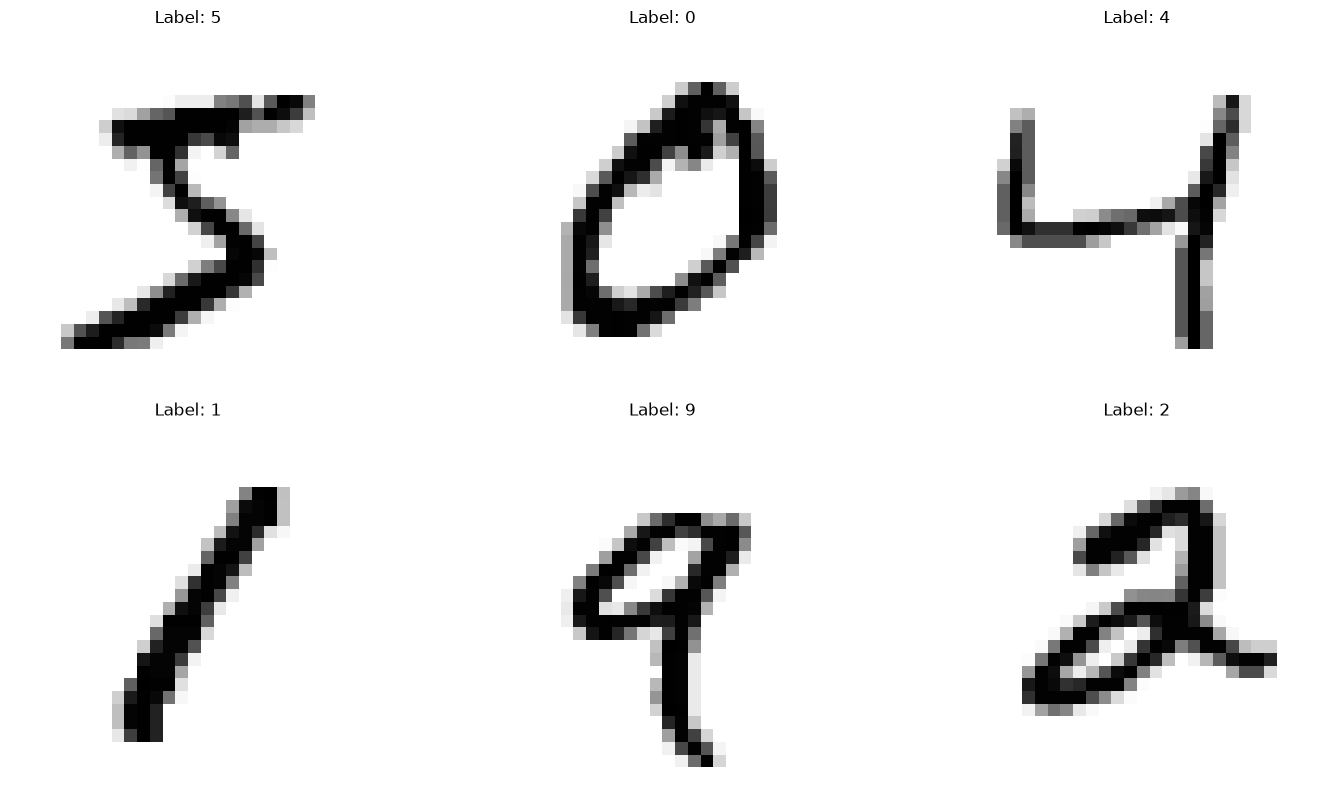

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i in range(6):
    ax[i].imshow(X_train[i], cmap="gray_r")
    ax[i].set_title(f"Label: {y_train[i]}")
    ax[i].axis('off')
fig.tight_layout()
plt.show()

Next, we divide the features by 255 (the maximum value of the pixels), so that all pixel values in the training and testing data are between 0 and 1. 

In the workshop, we will be working only with fully connected feed-forward networks (that don't exploit the spatial structure of the images like convolutional neural networks). As such, we also flatten all images to vectors.

In [25]:
# Rescale the data
X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape the data 
X_train = X_train.reshape((-1, 28 * 28))
X_test = X_test.reshape((-1, 28 * 28))

Lastly, we use convert the labels using a `LabelEncoder`.

In [26]:
# Converting the labels
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

### 🚩 Exercise 8 (CORE)

As a baseline model, create a pipeline (called `baseline`) that
- first uses PCA to reduce the dimension to 100
- then uses logistic regression with no penalty

Fit the pipeline to the data. Plot the confusion matrix and print the classification report. How many parameters does the logistic regression model have?

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import log_loss

# Code for your answer here

baseline = make_pipeline(
    PCA(n_components=100),
    LogisticRegression(penalty=None)
)

baseline.fit(X_train, y_train)

y_test_pred = baseline.predict(X_test)

print(confusion_matrix(y_true=y_test,y_pred=y_test_pred))

print(classification_report(y_true=y_test, y_pred=y_test_pred))

# Model has 10 parameters

C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


[[ 958    0    2    2    0    7    7    2    1    1]
 [   0 1110    3    2    0    1    4    2   13    0]
 [   7    9  923   15    6    6   13   11   34    8]
 [   3    2   19  914    0   29    2   12   19   10]
 [   2    2    7    2  910    0   10    3    8   38]
 [   8    3    7   37    9  773   15    5   30    5]
 [  13    3    8    1    8   11  909    2    3    0]
 [   1    6   27    6    7    1    0  947    2   31]
 [   8    9    5   26    9   34   11    7  860    5]
 [  11    6    1    7   33    7    0   24    9  911]]
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.97      0.98      0.97      1135
           2       0.92      0.89      0.91      1032
           3       0.90      0.90      0.90      1010
           4       0.93      0.93      0.93       982
           5       0.89      0.87      0.88       892
           6       0.94      0.95      0.94       958
           7       0.93      0.92   

Let's plot some of the images that were both correctly and incorrectly classified, along with the corresponding probabilities. 

Note: if you have called your model something other than `baseline`, please change the name in the code below.

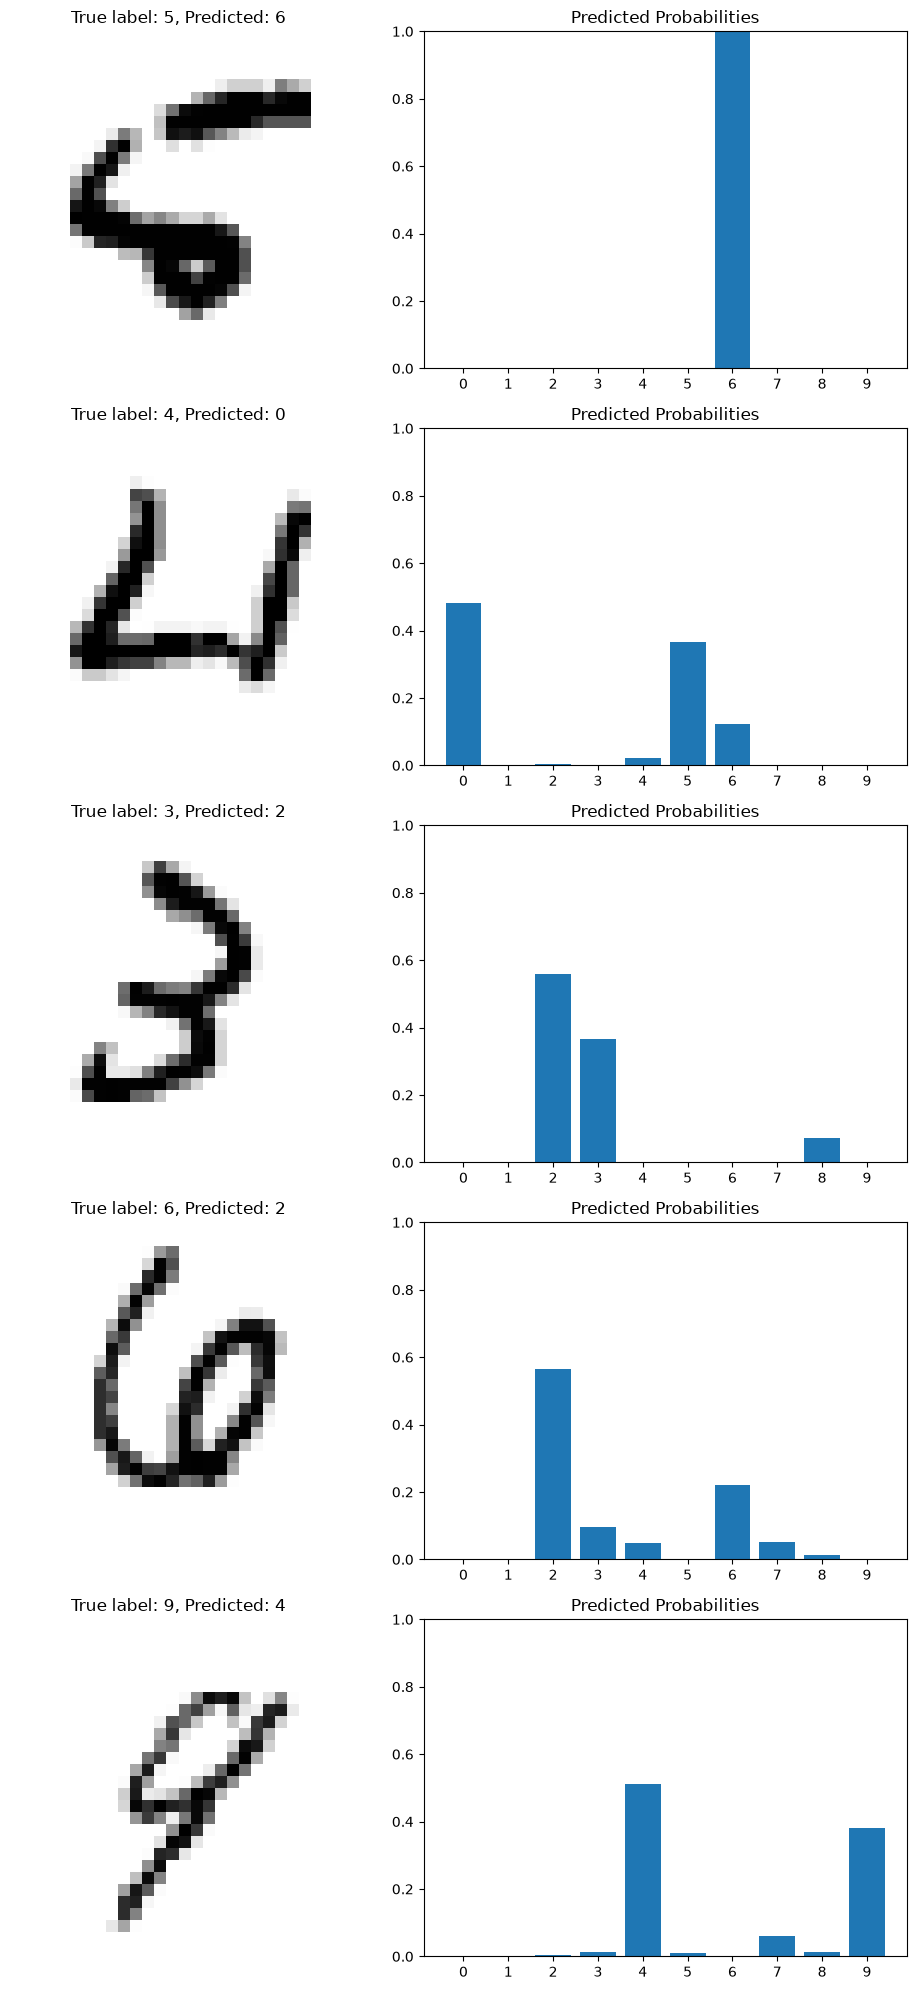

In [40]:
# indices of misclassified examples
misclas_indices = np.where(y_test != y_test_pred)[0]
# indices of correctly classified examples
clas_indices = np.where(y_test == y_test_pred)[0]

# For the first 5 misclassified examples, plot the image and a bar plot of the predicted probabilities for each class
fig, ax = plt.subplots(5, 2, figsize=(10, 20))
for i in range(5):
    idx = misclas_indices[i]
    ax[i, 0].imshow(X_test[idx].reshape(28, 28), cmap='gray_r')
    ax[i, 0].set_title(f'True label: {y_test[idx]}, Predicted: {y_test_pred[idx]}')
    ax[i, 0].axis('off')
    
    # Get predicted probabilities for each class
    y_prob = baseline.predict_proba(X_test[idx].reshape(1, -1))[0]
    
    # Bar plot of predicted probabilities
    ax[i, 1].bar(range(10), y_prob)
    ax[i, 1].set_xticks(range(10))
    ax[i, 1].set_xticklabels(label_encoder.classes_)
    ax[i, 1].set_ylim(0, 1)
    ax[i, 1].set_title('Predicted Probabilities')
fig.tight_layout()
plt.show()

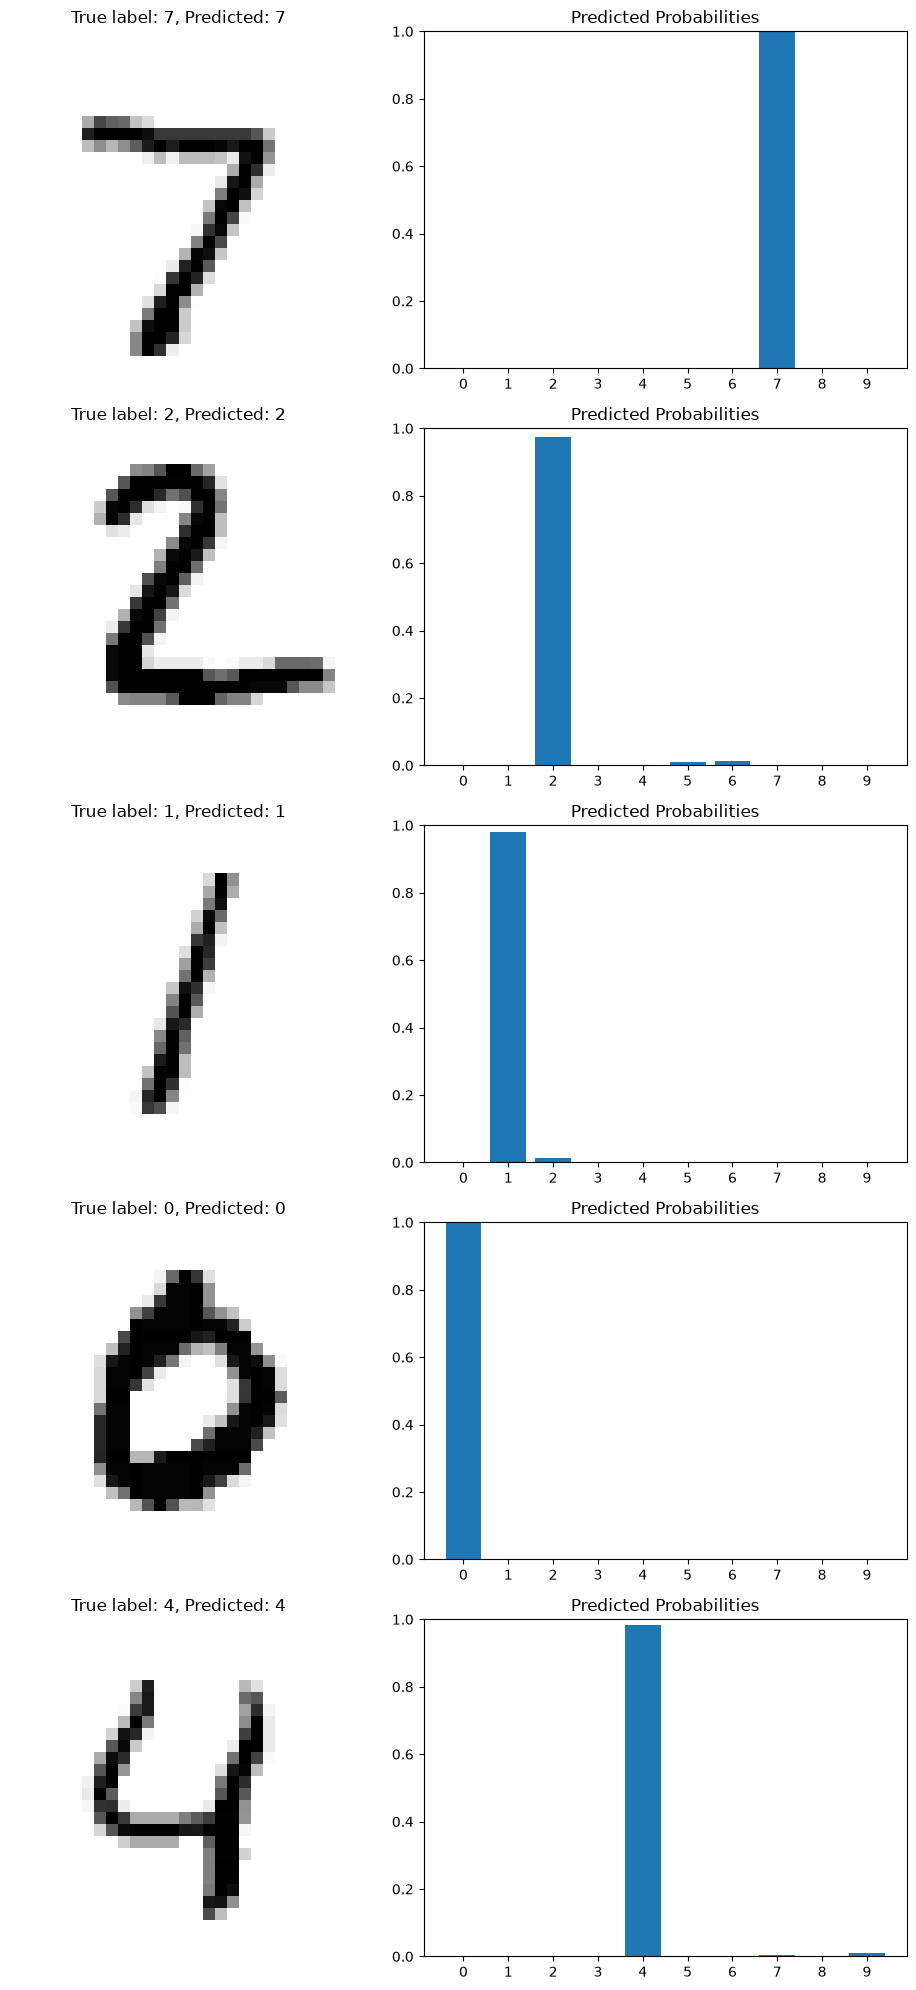

In [41]:
# For the first 5 correctly classified examples, plot the image and a bar plot of the predicted probabilities for each class
fig, ax = plt.subplots(5, 2, figsize=(10, 20))
for i in range(5):
    idx = clas_indices[i]
    ax[i, 0].imshow(X_test[idx].reshape(28, 28), cmap='gray_r')
    ax[i, 0].set_title(f'True label: {y_test[idx]}, Predicted: {y_test_pred[idx]}')
    ax[i, 0].axis('off')
    
    # Get predicted probabilities for each class
    y_prob = baseline.predict_proba(X_test[idx].reshape(1, -1))[0]
    
    # Bar plot of predicted probabilities
    ax[i, 1].bar(range(10), y_prob)
    ax[i, 1].set_xticks(range(10))
    ax[i, 1].set_xticklabels(label_encoder.classes_)
    ax[i, 1].set_ylim(0, 1)
    ax[i, 1].set_title('Predicted Probabilities')
fig.tight_layout()
plt.show()

It can be concerning when we have high probability/confidence for incorrectly classified images. This is quantified across all data points by the cross entropy loss, which for a single data points computes:

$$ L(y, p) = \sum_{c=1}^C y_c\log(p_c).$$

Notice that if the probability of the true class is close to 1, than the loss is zero, but if it is close to zero that the loss is high. 

We can report the cross entropy loss, averaged across all data points. 

In addition, through histogram showing the distribution of the probability of that $y$ is equal to the true test label, we can gain a more detailed understanding. We see that for the correctly classified images, over 4,000 images are correctly classified with a high probability. On the other hand, there are over 100 images that are misclassified with a high probability. 

Cross entropy loss: 0.28039545655373727


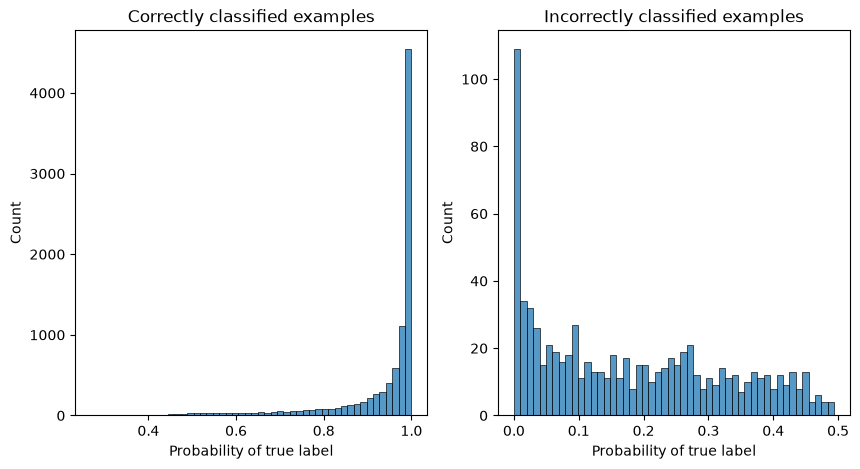

In [42]:
y_test_pred_prob = baseline.predict_proba(X_test)
print('Cross entropy loss:', log_loss(y_test, y_test_pred_prob, labels=label_encoder.classes_))

# Extract probabilility of correct label for each data point
prob_correct = y_test_pred_prob[np.arange(len(y_test)), y_test]

# Plot a histogram of the probabilities across data points, for correct or incorrect classification
fig, ax = plt.subplots(1,2,figsize = (10,5))
sns.histplot(x = prob_correct[clas_indices], bins=50, ax=ax[0])
ax[0].set_title('Correctly classified examples')
ax[0].set_xlabel('Probability of true label')
sns.histplot(x = prob_correct[misclas_indices], bins=50, ax=ax[1])
ax[1].set_xlabel('Probability of true label')
ax[1].set_title('Incorrectly classified examples')
plt.show()

### 🚩 Exercise 9 (CORE)

Next, let's fit a fully-connected feed forwared neural network. Note that we need to one-hot encoding the output labels for use in keras in the multiclass setting.

- Define and compile a model with one hidden layer of 128 neurons and ReLU activation. For the final layer, use a softmax with 10 units to obtain the probabilities for each class. Here use the categorical cross entropy loss. 
- Fit the model and train for 10 epochs with a batch size of 128 and a 10% validation split, and plot the loss and accuracy for the training and validation sets as a function of epochs.
- Plot the confusion matrix and print the classification report on the test data.
- Visualise some the test images, along with their probabilities for both correctly and incorrectly classified images.
- Print the cross entropy loss on the test data, and visualise the distribution of the probability of the true labels for correctly and incorrectly classified test points.

In [43]:
# First create a one-hot encoding of the labels for use in Keras
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)
# Print the first few rows before and after one-hot encoding
print("Original labels:", y_train[:5])
print("One-hot encoded labels:\n", y_train_cat[:5])

Original labels: [5 0 4 1 9]
One-hot encoded labels:
 [[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8967 - loss: 0.3732 - val_accuracy: 0.9553 - val_loss: 0.1697
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9489 - loss: 0.1745 - val_accuracy: 0.9653 - val_loss: 0.1273
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9636 - loss: 0.1268 - val_accuracy: 0.9680 - val_loss: 0.1094
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9718 - loss: 0.0983 - val_accuracy: 0.9715 - val_loss: 0.0992
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9774 - loss: 0.0792 - val_accuracy: 0.9728 - val_loss: 0.0937
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9819 - loss: 0.0652 - val_accuracy: 0.9738 - val_loss: 0.0911
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9855 - loss: 0.0544 - val_accuracy: 0.9747 - val_loss: 0.0885
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9880 - loss: 0.0457 - val_accuracy: 0.

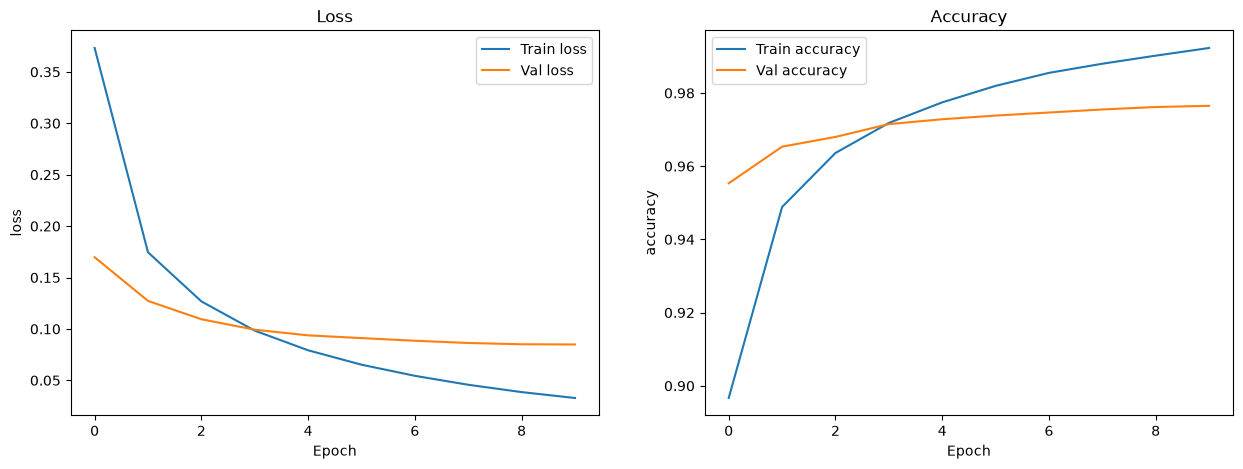

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 797us/step
[[ 965    0    2    3    1    3    3    0    2    1]
 [   0 1117    3    2    0    1    3    0    9    0]
 [   1    0 1012    5    1    0    3    2    8    0]
 [   1    0    1  998    0    3    0    1    4    2]
 [   3    0    5    1  934    1   10    4    5   19]
 [   2    0    0    9    1  867    7    1    3    2]
 [   3    2    2    1    1    4  943    0    2    0]
 [   0    3    8   10    0    2    0  991    7    7]
 [   2    0    3   10    0    1    2    1  954    1]
 [   1    2    0    7    3    3    1    3    8  981]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       980
           1       0.99      0.98      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.95      0.99      0.97      1010
           4       0.99      0.95      0.97       982
           5       0.98      0.97      0.98       892
           6       0.97      0.98      0.98    

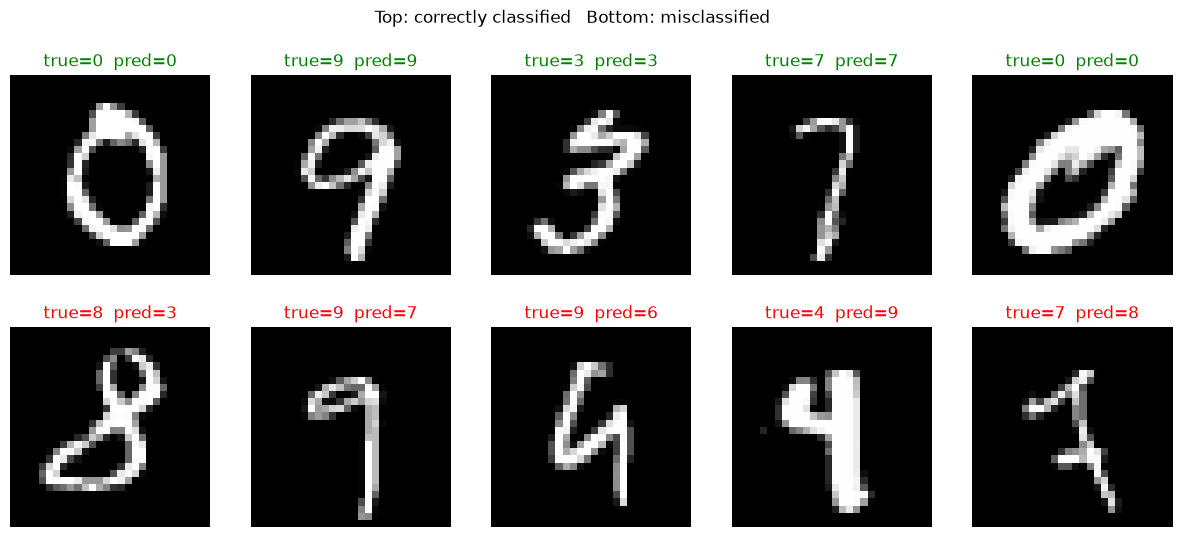

Cross entropy loss: 0.08381252735853195


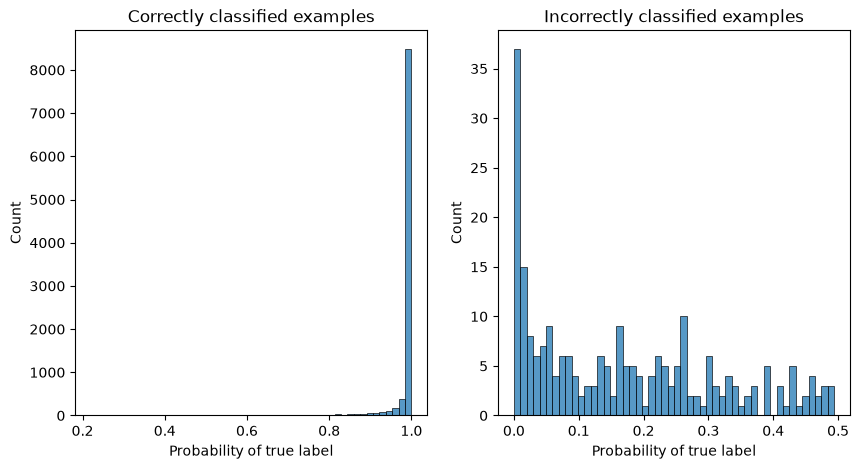

In [48]:

D = X_train.shape[1]
input_layer  = keras.Input(shape=(D,))
hidden_layer = keras.layers.Dense(128, activation='relu')(input_layer)
output_layer = keras.layers.Dense(10,  activation='softmax')(hidden_layer)
model_hidden4 = keras.Model(inputs=input_layer, outputs=output_layer)
model_hidden4.summary()

model_hidden4.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=[
        keras.metrics.CategoricalAccuracy(name='accuracy'),
    ],
)

history = model_hidden4.fit(
    X_train, y_train_cat,
    epochs=10, batch_size=128, validation_split=0.1,
).history

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for i, key in enumerate(['loss', 'accuracy']):
    ax[i].plot(history[key],         label=f'Train {key}')
    ax[i].plot(history[f'val_{key}'],label=f'Val {key}')
    ax[i].set_title(key.capitalize())
    ax[i].set_xlabel('Epoch'); ax[i].set_ylabel(key); ax[i].legend()
plt.show()


y_test_pred_prob = model_hidden4.predict(X_test)          # (N, 10) probabilities
y_test_pred      = y_test_pred_prob.argmax(axis=1)

print(confusion_matrix(y_true=y_test, y_pred=y_test_pred))
print(classification_report(y_true=y_test, y_pred=y_test_pred))


correct_mask = (y_test_pred == y_test)
clas_indices    = np.where(correct_mask)[0]
misclas_indices = np.where(~correct_mask)[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes[0], np.random.choice(clas_indices, 5, replace=False)):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')   # adjust shape if not MNIST
    ax.set_title(f"true={y_test[i]}  pred={y_test_pred[i]}", color='green')
    ax.axis('off')
for ax, i in zip(axes[1], np.random.choice(misclas_indices, 5, replace=False)):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"true={y_test[i]}  pred={y_test_pred[i]}", color='red')
    ax.axis('off')
plt.suptitle("Top: correctly classified   Bottom: misclassified")
plt.show()


print('Cross entropy loss:', log_loss(y_test, y_test_pred_prob))

prob_true = y_test_pred_prob[np.arange(len(y_test)), y_test]   # p(true label) per sample

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(x=prob_true[clas_indices],    bins=50, ax=ax[0])
ax[0].set_title('Correctly classified examples')
ax[0].set_xlabel('Probability of true label')
sns.histplot(x=prob_true[misclas_indices], bins=50, ax=ax[1])
ax[1].set_title('Incorrectly classified examples')
ax[1].set_xlabel('Probability of true label')
plt.show()


### 🚩 Exercise 10 (EXTRA - Feedback will be given)

Comment on the following:

a. Do you think you need to train the model for more epochs? 

b. Which model do you prefer: the baseline logisitic regression or the neural network? Consider the trade-off between: the number of parameters and predictive performance.

_Type your answer here_

### 🚩 Exercise 11 (EXTRA)

Let's explore a deeper architecture.

- Build a deeper network with three hidden layers, with $D_1 = 128, D_2 = 64, D_1 = 32$ neurons and ReLU activation, and an output layer with 10 neurons and softmax activation.

- Compile and train the model with the same setting as the shallow model.

- Plot the loss and accuracy for the training and validation sets as a function of epochs. Do you think more epochs are needed?

- Plot the confusion matrix, print the classification report, and cross entropy loss. Visualise some the images, along with their probabilities for both correctly and incorrectly classified images.

- Which model do you prefer? Consider the trade-off between: the number of parameters and predictive performance.

In [ ]:
# Code for your answer here!

_Type your answer here_

### 🚩 Exercise 12 (CORE)

Have you used any form of generative AI when working on this assessment? If so, describe how you used which tool, and what you have learned from it.

_Type your answer here_

Yes, I used generative AI to aid me in some of the core questions, using the university ELM. Especially when plotting and the sytax neeed for that, as well as understanding the chain logic for the modeliing the NN, and how the compile works with them. I used it as a tool, which meant i now am able to do those mentioned techniques myself. 

# Completing the Worksheet

At this point you have hopefully been able to complete all the CORE exercises and attempted the EXTRA ones. Now is a good time to check the reproducibility of this document by restarting the notebook's kernel and rerunning all cells in order.

Before generating the PDF, please **change 'Student 1', 'Student 2' and 'Student 3' at the top of the notebook to include your name(s)**.

Once that is done and you are happy with everything, you can then run the following cell to generate your PDF. 

In [53]:
!jupyter nbconvert --to pdf mlp_week09.ipynb 

[NbConvertApp] Converting notebook mlp_week09.ipynb to pdf
[NbConvertApp] Support files will be in mlp_week09_files\
[NbConvertApp] Making directory .\mlp_week09_files
[NbConvertApp] Writing 257549 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 3840637 bytes to mlp_week09.pdf
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\thoma\AppData\Roaming\Python\Python312\Scripts\jupyter-nbconvert.EXE\__main__.py", line 5, in <module>
  File "C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\jupyter_core\application.py", line 284, in launch_instance
    super().launch_instance(argv=argv, **kwa